# Fit Pedestal Model to TVAC Images

In [27]:
import pathlib
import astropy.io.fits
import numpy as np
import xarray
import matplotlib.pyplot as plt

from astropy.visualization import AsymmetricPercentileInterval, ImageNormalize

In [ ]:
#import distributed
#client = distributed.Client(address='tcp://127.0.0.1:38557')

In [2]:
moxsi_data_dir = pathlib.Path('/data1/moxsi')

Load the list of "clean" images from TVAC that we'll use to determine the fitting parameters

In [3]:
ds = xarray.open_zarr(moxsi_data_dir / 'notebooks' / 'clean_tvac_images.zarr')

## What is a reasonable range of the "clean" images for fitting?

In [3]:
with (moxsi_data_dir / 'notebooks' / 'clean_TVAC_images.txt').open() as f:
    clean_tvac_images = f.read().splitlines()
clean_tvac_images = [pathlib.Path(f) for f in clean_tvac_images]

In [4]:
ds = list_of_files_to_ds(clean_tvac_images)

100%|██████████| 42987/42987 [03:32<00:00, 202.31it/s]


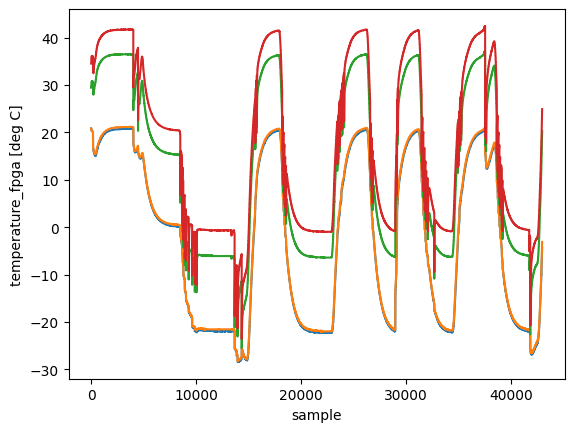

In [20]:
ds.temperature_detector_0.plot()
ds.temperature_detector_1.plot()
ds.temperature_adc.plot()
ds.temperature_fpga.plot()
#ax2 = plt.gca().twinx()
#ds.exposure_time.plot(ax=ax2)

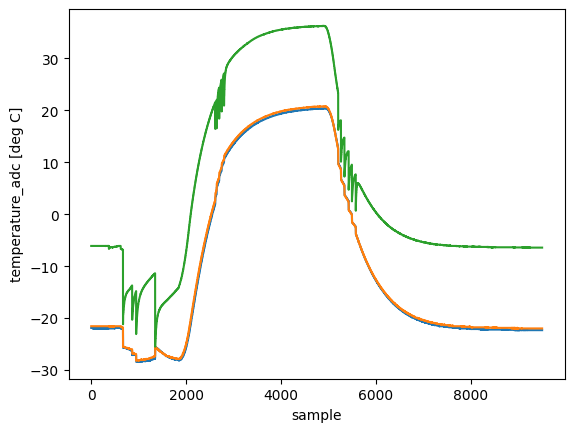

In [24]:
sample_slice = np.s_[13000:22500]
ds.isel(sample=sample_slice).temperature_detector_0.plot()
ds.isel(sample=sample_slice).temperature_detector_1.plot()
ds.isel(sample=sample_slice).temperature_adc.plot()
#ax2 = plt.gca().twinx()
#ds.isel(sample=sample_slice).exposure_time.plot(ax=ax2, alpha=0.1)

In [25]:
ds_sel = list_of_files_to_ds(clean_tvac_images[13000:22500])

100%|██████████| 9500/9500 [00:39<00:00, 239.67it/s]


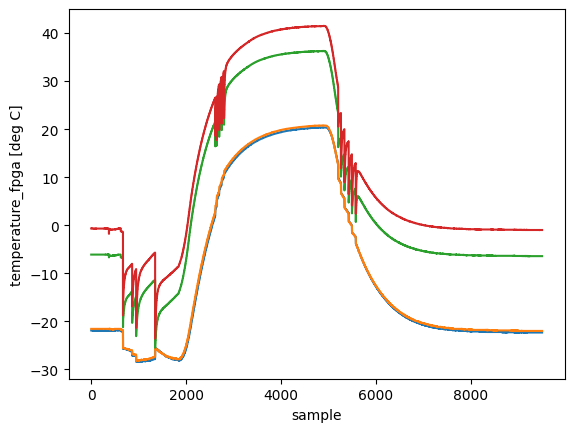

In [26]:
ds_sel.temperature_detector_0.plot()
ds_sel.temperature_detector_1.plot()
ds_sel.temperature_adc.plot()
ds_sel.temperature_fpga.plot()

## Load the fitting coefficients

In [6]:
da_fit_coeffs = xarray.open_dataarray(moxsi_data_dir / 'notebooks' / 'fit_coefficients_tvac.nc')

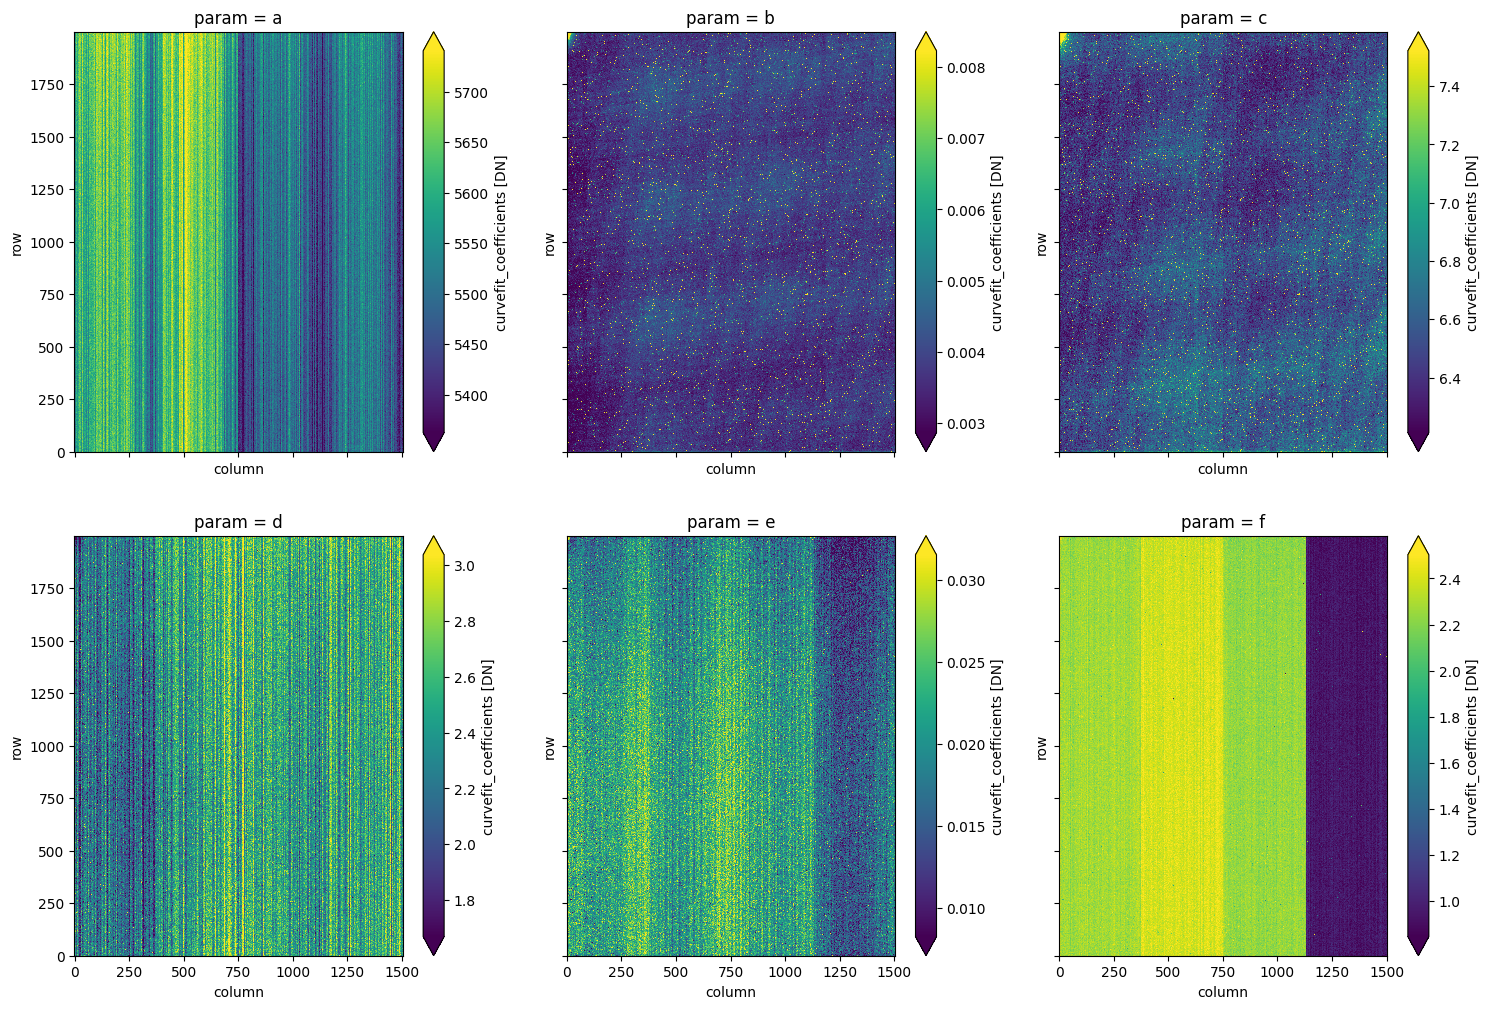

In [8]:
size = 6 
fig,axes = plt.subplots(2,3,figsize=(size*3,size*2),sharex=True,sharey=True)
for i,ax in enumerate(axes.flatten()):
    vmin, vmax = AsymmetricPercentileInterval(1,99).get_limits(da_fit_coeffs[...,i].data)
    da_fit_coeffs[...,i].plot.imshow(ax=ax, vmin=max(0,vmin), vmax=vmax)

In [9]:
range_dict = {'a': [5200,6000],
              'b': [0.0005, 0.01],
              'c': [5,10.0],
              'd': [0.5,5],
              'e': [0.002,0.07],
              'f': [0.5,3.0]}

/tmp/ipykernel_642006/386262693.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc=2, frameon=False)


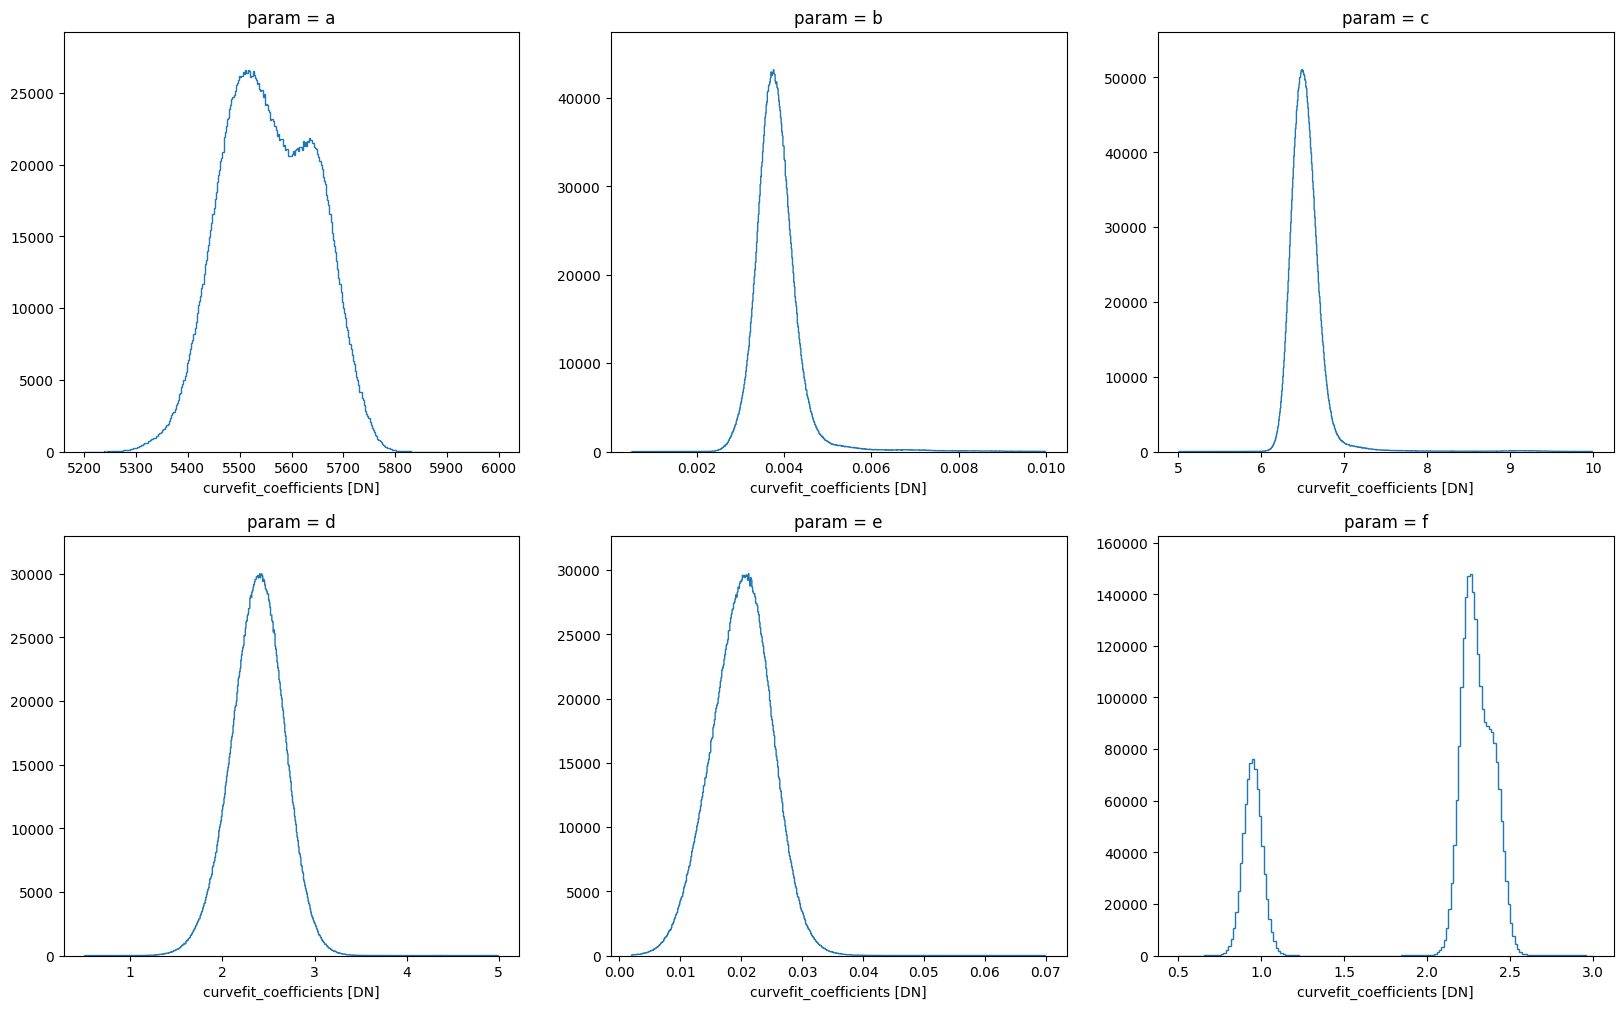

In [11]:
fig,axes = plt.subplots(2,3,figsize=(20,12),sharex=False,sharey=False)
bin_edges = {}
for i,(ax,param) in enumerate(zip(axes.flatten(),da_fit_coeffs.param.data)):
    if (range := range_dict.get(str(param))) is None:
        range = AsymmetricPercentileInterval(0.5,99.5).get_limits(da_fit_coeffs[...,i].data)
    h_all, be, _ = da_fit_coeffs.sel(param=param).plot.hist(ax=ax, bins='scott', range=range, histtype='step', log=False, color='C0')
    ax.set_ylim(0, 1.1*h_all.max())
    if param == 'a':
        ax.legend(loc=2, frameon=False)

In [13]:
def pedestal_func(ds, coeffs):
    t_det0 = ds.temperature_detector_0
    exposure = ds.exposure_time
    t_adc = ds.temperature_adc
    return (coeffs.sel(param='a') 
            + coeffs.sel(param='f') * t_adc
            + coeffs.sel(param='b') * exposure * np.exp(t_det0 / coeffs.sel(param='c'))
            + coeffs.sel(param='d') * t_det0
            + coeffs.sel(param='e') * t_det0**2)

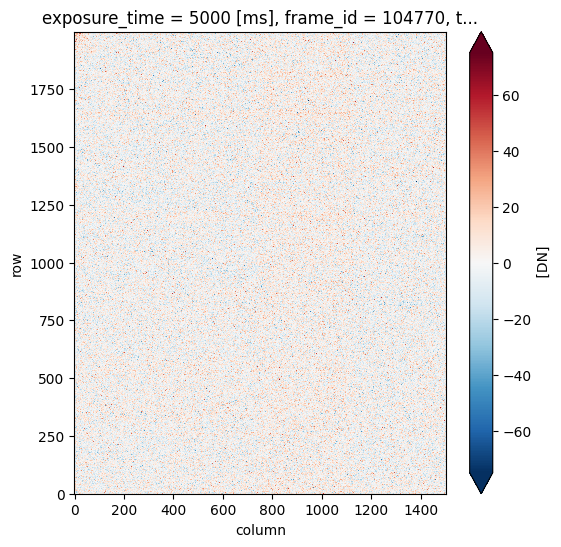

In [35]:
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=-75,vmax=75)
slice_sample = np.s_[1000:1500]
idx_sample = 250
ds_slice = ds.isel(sample=slice_sample)
ds_slice_sub = (ds_slice['data'] - pedestal_func(ds_slice, da_fit_coeffs)).compute()
ds_slice_sub[idx_sample].plot.imshow(ax=ax, norm=norm);

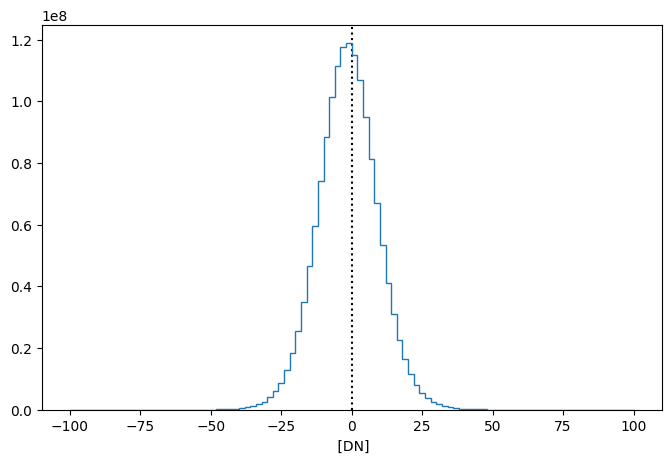

In [36]:
fig = plt.figure(figsize=(8,5))
ax = fig.add_subplot()
ax.axvline(x=0, ls=':', color='k');
_,be,_ = ds_slice_sub.plot.hist(ax=ax,bins=100,range=(-100,100),histtype='step',log=False);